In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("sms_spam_sample_2000.csv")
df['original_message'] = df['message']
df['cleaned_message'] = df['message']

In [3]:
print("the information of data")
df.info()

the information of data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   label             2000 non-null   object
 1   message           2000 non-null   object
 2   original_message  2000 non-null   object
 3   cleaned_message   2000 non-null   object
dtypes: object(4)
memory usage: 62.6+ KB


In [4]:
print(df['label'].value_counts())

label
ham     1732
spam     268
Name: count, dtype: int64


In [5]:
df['cleaned_message'].head()

,cleaned_message
0,"Bears Pic Nick, and Tom, Pete and ... Dick. In..."
1,Thanks for yesterday sir. You have been wonder...
2,"You aren't coming home between class, right? I..."
3,"I'm an actor. When i work, i work in the eveni..."
4,Oh k k:)but he is not a big hitter.anyway good


In [6]:
df['cleaned_message'].tail()

,cleaned_message
1995,Then. You are eldest know.
1996,"Lol ... Oh no babe, I wont be sliding into you..."
1997,I had it already..sabarish asked me to go..
1998,Oic cos me n my sis got no lunch today my dad ...
1999,HI ITS JESS I DONT KNOW IF YOU ARE AT WORK BUT...


In [7]:
print("the number of missing value ")
print(df['cleaned_message'].isnull().sum())

the number of missing value 
0


In [8]:
print("the number of dublicated data")
print(df.duplicated().sum())


the number of dublicated data
73


In [9]:
print("the describtion of data")
print(df['cleaned_message'].describe())

the describtion of data
count                       2000
unique                      1927
top       Sorry, I'll call later
freq                          12
Name: cleaned_message, dtype: object


In [10]:
print("the shape of data")
print(df.shape)
df['cleaned_message'].shape

the shape of data
(2000, 4)


(2000,)

In [11]:
print("the shape of data")
print(df.shape)
df['original_message'].shape

the shape of data
(2000, 4)


(2000,)

In [12]:
df.drop_duplicates(
    subset=['label', 'cleaned_message'],
    keep='first',
    inplace=True
)

In [13]:
print("The number of Dublicated message after cleaning")
print(df.duplicated().sum())

The number of Dublicated message after cleaning
0


In [14]:
import re
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [15]:
stop_words = stopwords.words('english')

print(stop_words[:25])

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both']


In [16]:
df['cleaned_message'] = df['cleaned_message'].str.lower()
df['cleaned_message'].head()

,cleaned_message
0,"bears pic nick, and tom, pete and ... dick. in..."
1,thanks for yesterday sir. you have been wonder...
2,"you aren't coming home between class, right? i..."
3,"i'm an actor. when i work, i work in the eveni..."
4,oh k k:)but he is not a big hitter.anyway good


In [17]:
print("The data after deleting HTML Tage")
df['cleaned_message'] = df['cleaned_message'].str.replace(r'<.*?>', '', regex=True)

df['cleaned_message'].head()

The data after deleting HTML Tage


,cleaned_message
0,"bears pic nick, and tom, pete and ... dick. in..."
1,thanks for yesterday sir. you have been wonder...
2,"you aren't coming home between class, right? i..."
3,"i'm an actor. when i work, i work in the eveni..."
4,oh k k:)but he is not a big hitter.anyway good


In [18]:
import string
print("The data after deleting punctuation")
df['cleaned_message'] = df['cleaned_message'].str.replace(
    '[' + string.punctuation + ']', ' ', regex=True
)
df['cleaned_message'].head()

The data after deleting punctuation


,cleaned_message
0,bears pic nick and tom pete and dick in...
1,thanks for yesterday sir you have been wonder...
2,you aren t coming home between class right i...
3,i m an actor when i work i work in the eveni...
4,oh k k but he is not a big hitter anyway good


In [19]:
print("The data after deleting numbers")
df['cleaned_message'] = df['cleaned_message'].str.replace(r'\d+', '', regex=True)

df['cleaned_message'].head()

The data after deleting numbers


,cleaned_message
0,bears pic nick and tom pete and dick in...
1,thanks for yesterday sir you have been wonder...
2,you aren t coming home between class right i...
3,i m an actor when i work i work in the eveni...
4,oh k k but he is not a big hitter anyway good


In [20]:
print("the data after deleting stopwords")
stop_words = set(stopwords.words('english'))

stop_words = stop_words - {'not', 'no', 'nor'}
df['cleaned_message'] = df['cleaned_message'].apply(
    lambda x: ' '.join([word for word in x.split() if word not in stop_words])
)

df['cleaned_message'].head()

the data after deleting stopwords


,cleaned_message
0,bears pic nick tom pete dick fact types try ga...
1,thanks yesterday sir wonderful hope enjoyed bu...
2,coming home class right need work shower
3,actor work work evening sleep late since unemp...
4,oh k k not big hitter anyway good


In [21]:

df['original_message'].head()


,original_message
0,"Bears Pic Nick, and Tom, Pete and ... Dick. In..."
1,Thanks for yesterday sir. You have been wonder...
2,"You aren't coming home between class, right? I..."
3,"I'm an actor. When i work, i work in the eveni..."
4,Oh k k:)but he is not a big hitter.anyway good


In [22]:
df['cleaned_message'].head()

,cleaned_message
0,bears pic nick tom pete dick fact types try ga...
1,thanks yesterday sir wonderful hope enjoyed bu...
2,coming home class right need work shower
3,actor work work evening sleep late since unemp...
4,oh k k not big hitter anyway good


In [23]:
df.drop_duplicates(
    subset=['label', 'cleaned_message'],
    keep='first',
    inplace=True
)

In [24]:
print("Shape:", df.shape)
print("Duplicates:", df.duplicated(subset=['label', 'cleaned_message']).sum())

Shape: (1905, 4)
Duplicates: 0


In [25]:
print("Missing values:", df['cleaned_message'].isnull().sum())
print("Duplicated messages:", df['cleaned_message'].duplicated().sum())
print("Final shape:", df.shape)


Missing values: 0
Duplicated messages: 0
Final shape: (1905, 4)


In [26]:
print(df['label'].value_counts())

label
ham     1664
spam     241
Name: count, dtype: int64


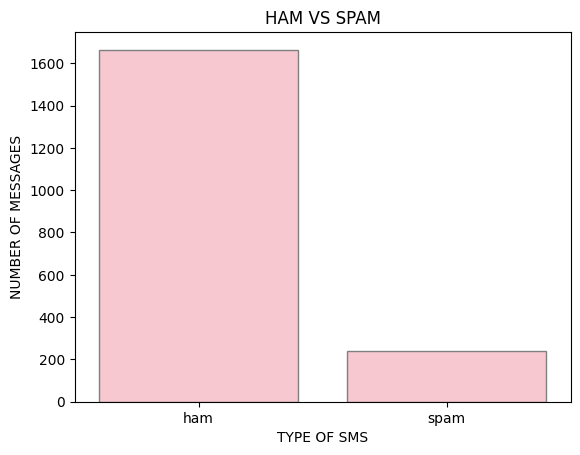

In [27]:
sns.barplot(
    x=df['label'].value_counts().index,
    y=df['label'].value_counts().values,
    color='pink',
    edgecolor='gray'
)

plt.title('HAM VS SPAM')
plt.xlabel('TYPE OF SMS')
plt.ylabel('NUMBER OF MESSAGES')
plt.show()

In [28]:
print(" The number of missing value",df['cleaned_message'].isnull().sum())
print("The number of dublicated message",df.duplicated().sum())
print("The shape of data after cleaning",df.shape)

 The number of missing value 0
The number of dublicated message 0
The shape of data after cleaning (1905, 4)


In [29]:
df.to_csv('cleaned_sms_spam.csv', index=False)

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [31]:
X = df['cleaned_message']
y = df['label']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1905,)
Target shape: (1905,)


In [32]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 1333
Validation: 286
Testing: 286


In [33]:
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)

X_val_tfidf = tfidf.transform(X_val)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Validation TF-IDF Shape:", X_val_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("Vocabulary Size:", len(tfidf.vocabulary_))

Training TF-IDF Shape: (1333, 3462)
Validation TF-IDF Shape: (286, 3462)
Testing TF-IDF Shape: (286, 3462)
Vocabulary Size: 3462


In [34]:
print("TF-IDF Vectorization completed successfully!")
print("No. of training samples:", X_train_tfidf.shape[0])
print("No. of features:", X_train_tfidf.shape[1])
print("Vocabulary size:", len(tfidf.vocabulary_))

TF-IDF Vectorization completed successfully!
No. of training samples: 1333
No. of features: 3462
Vocabulary size: 3462


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [36]:
C_values = [0.01, 0.1, 1, 10, 100]

best_model = None
best_C = None
best_f1 = 0

for c in C_values:
    model = LogisticRegression(C=c, max_iter=1000)
    model.fit(X_train_tfidf, y_train)

    y_val_pred = model.predict(X_val_tfidf)

    f1 = f1_score(y_val, y_val_pred, pos_label='spam')

    print(f"C = {c}, Validation F1-score = {f1:.4f}")

    if f1 > best_f1:
        best_f1 = f1
        best_C = c
        best_model = model

print("\nBest C:", best_C)
print("Best Validation F1-score:", best_f1)

C = 0.01, Validation F1-score = 0.0000
C = 0.1, Validation F1-score = 0.0000
C = 1, Validation F1-score = 0.5098
C = 10, Validation F1-score = 0.8182
C = 100, Validation F1-score = 0.8657

Best C: 100
Best Validation F1-score: 0.8656716417910447


In [37]:

y_test_pred = best_model.predict(X_test_tfidf)


accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred, pos_label='spam')
recall = recall_score(y_test, y_test_pred, pos_label='spam')
f1 = f1_score(y_test, y_test_pred, pos_label='spam')

print("Logistic Regression Test Results")
print("--------------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Logistic Regression Test Results
--------------------------------
Accuracy: 0.972
Precision: 0.9375
Recall: 0.8333
F1-score: 0.8824

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      0.99      0.98       250
        spam       0.94      0.83      0.88        36

    accuracy                           0.97       286
   macro avg       0.96      0.91      0.93       286
weighted avg       0.97      0.97      0.97       286



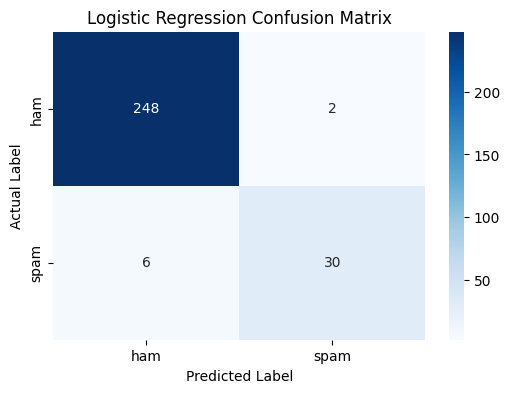

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_test_pred, labels=['ham', 'spam'])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['ham', 'spam'],
    yticklabels=['ham', 'spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

In [39]:
import joblib

joblib.dump(best_model, 'logistic_regression_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("Model and TF-IDF Vectorizer saved successfully!")

Model and TF-IDF Vectorizer saved successfully!


In [40]:
from google.colab import files

files.download('logistic_regression_model.pkl')
files.download('tfidf_vectorizer.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [42]:
C_values=[0.01,0.1,1,10,100]
best_model_svm= None
best_C_svm= None
best_f1_svm= 0
for c in C_values:

    model = LinearSVC(C=c, max_iter=10000)

    model.fit(X_train_tfidf, y_train)

    y_val_pred = model.predict(X_val_tfidf)

    f1 = f1_score(y_val, y_val_pred, pos_label='spam')

    print(f"C = {c}, Validation F1-score = {f1:.4f}")

    if f1 > best_f1_svm:
        best_f1_svm = f1
        best_C_svm = c
        best_model_svm = model

print("\nBest C:", best_C_svm)
print("Best Validation F1-score:", best_f1_svm)


C = 0.01, Validation F1-score = 0.0000
C = 0.1, Validation F1-score = 0.6182
C = 1, Validation F1-score = 0.8788
C = 10, Validation F1-score = 0.8485
C = 100, Validation F1-score = 0.8485

Best C: 1
Best Validation F1-score: 0.8787878787878788


In [43]:
y_test_pred_svm = best_model_svm.predict(X_test_tfidf)

print("Linear SVM Test Accuracy:",
      accuracy_score(y_test, y_test_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_svm))

Linear SVM Test Accuracy: 0.972027972027972

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      0.99      0.98       250
        spam       0.94      0.83      0.88        36

    accuracy                           0.97       286
   macro avg       0.96      0.91      0.93       286
weighted avg       0.97      0.97      0.97       286



In [44]:
cm_svm = confusion_matrix(
    y_test,
    y_test_pred_svm,
    labels=['ham', 'spam']
)

print("Linear SVM Confusion Matrix:")
print(cm_svm)

Linear SVM Confusion Matrix:
[[248   2]
 [  6  30]]


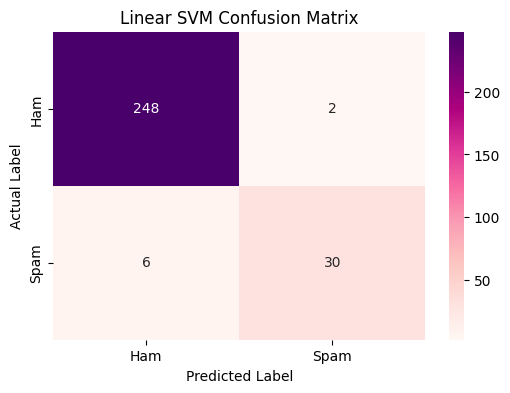

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_svm = confusion_matrix(
    y_test,
    y_test_pred_svm,
    labels=['ham', 'spam']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='RdPu',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title('Linear SVM Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

In [46]:
print(type(X_test))
print(X_test.index[:5])

<class 'pandas.core.series.Series'>
Index([180, 1549, 523, 1162, 1503], dtype='int64')


In [47]:
# Create a DataFrame for test predictions
errors_svm = pd.DataFrame({
    'cleaned_message': X_test,
    'actual': y_test,
    'predicted': y_test_pred_svm
})

# Add original messages
errors_svm['original_message'] = df.loc[
    errors_svm.index, 'original_message'
]

# Messages that are Ham but predicted as Spam
false_positive = errors_svm[
    (errors_svm['actual'] == 'ham') &
    (errors_svm['predicted'] == 'spam')
]

# Messages that are Spam but predicted as Ham
false_negative = errors_svm[
    (errors_svm['actual'] == 'spam') &
    (errors_svm['predicted'] == 'ham')
]

print("Ham predicted as Spam:")
display(false_positive)

print("\nSpam predicted as Ham:")
display(false_negative)

Ham predicted as Spam:


,cleaned_message,actual,predicted,original_message
269,noice text,ham,spam,Noice. Text me when you're here
1303,always yahoo messenger send message get may se...,ham,spam,I'm always on yahoo messenger now. Just send t...



Spam predicted as Ham:


,cleaned_message,actual,predicted,original_message
1416,life never much fun great came made truly spec...,spam,ham,LIFE has never been this much fun and great un...
1422,next amazing xxx picsfree video sent enjoy one...,spam,ham,Your next amazing xxx PICSFREE1 video will be ...
200,believe true incredible txts reply g learn tru...,spam,ham,You won't believe it but it's true. It's Incre...
856,recieve tone within next hrs terms conditions ...,spam,ham,You will recieve your tone within the next 24h...
549,want get laid tonight want real dogging locati...,spam,ham,Want 2 get laid tonight? Want real Dogging loc...
224,hello darling today would love chat dont tell ...,spam,ham,Hello darling how are you today? I would love ...


In [48]:
import joblib

joblib.dump(best_model_svm, 'linear_svm_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer_svm.pkl')

print("Linear SVM model and TF-IDF Vectorizer saved successfully!")

Linear SVM model and TF-IDF Vectorizer saved successfully!


In [49]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = {
    'Logistic Regression': [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, pos_label='spam'),
        recall_score(y_test, y_test_pred, pos_label='spam'),
        f1_score(y_test, y_test_pred, pos_label='spam')
    ],

    'Linear SVM': [
        accuracy_score(y_test, y_test_pred_svm),
        precision_score(y_test, y_test_pred_svm, pos_label='spam'),
        recall_score(y_test, y_test_pred_svm, pos_label='spam'),
        f1_score(y_test, y_test_pred_svm, pos_label='spam')
    ]
}

comparison_df = pd.DataFrame(
    results,
    index=['Accuracy', 'Precision', 'Recall', 'F1-score']
)

display(comparison_df.round(4))

,Logistic Regression,Linear SVM
Accuracy,0.9720,0.9720
Precision,0.9375,0.9375
Recall,0.8333,0.8333
F1-score,0.8824,0.8824


In [50]:
from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier(
    estimators=[
        ('lr', best_model),
        ('svm', best_model_svm)
    ],
    voting='hard'
)

voting_model.fit(X_train_tfidf, y_train)

print("Voting Classifier trained successfully!")

Voting Classifier trained successfully!


In [51]:
from sklearn.metrics import f1_score

y_val_pred_voting = voting_model.predict(X_val_tfidf)

voting_val_f1 = f1_score(
    y_val,
    y_val_pred_voting,
    pos_label='spam'
)

print("Voting Validation F1-score:", voting_val_f1)

Voting Validation F1-score: 0.8787878787878788


In [52]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

y_test_pred_voting = voting_model.predict(X_test_tfidf)

print("Voting Test Accuracy:",
      accuracy_score(y_test, y_test_pred_voting))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_voting))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_test_pred_voting,
    labels=['ham', 'spam']
))

Voting Test Accuracy: 0.972027972027972

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      0.99      0.98       250
        spam       0.94      0.83      0.88        36

    accuracy                           0.97       286
   macro avg       0.96      0.91      0.93       286
weighted avg       0.97      0.97      0.97       286


Confusion Matrix:
[[248   2]
 [  6  30]]


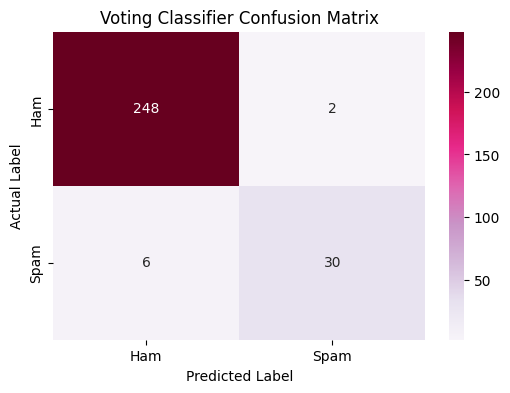

In [53]:
cm_voting = confusion_matrix(
    y_test,
    y_test_pred_voting,
    labels=['ham', 'spam']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_voting,
    annot=True,
    fmt='d',
    cmap='PuRd',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title('Voting Classifier Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

In [54]:
joblib.dump(voting_model, 'voting_classifier_model.pkl')

print("Voting Classifier saved successfully!")

Voting Classifier saved successfully!


In [55]:
from google.colab import files

files.download('voting_classifier_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:
from google.colab import files

files.download('linear_svm_model.pkl')
files.download('voting_classifier_model.pkl')

files.download('tfidf_vectorizer_svm.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>